### 🔴 Section 1: Implement for MA's

#### ⚪ 1. Libraries

In [1]:
### Cell 1 
import pandas as pd
import scipy.io
import numpy as np
import time
from scipy.io import loadmat
from sklearn.preprocessing import MinMaxScaler
from scipy.spatial.distance import cdist
from sklearn.metrics import roc_auc_score, average_precision_score

#### ⚪ 2. Extract indices from .csv file

In [3]:
### Cell 2
# --- Configuration ---
csv_file_path = '/media/mine/Mine/3.Main-Ubuntu-Envs/2.Thesis-Env/3.Datasets/mammographyori.csv'

def get_ma_indices(df, feature_name, low, high):
    condition = (df[feature_name] >= low) & (df[feature_name] <= high)
    subset = df[condition]
    indices = subset.index.to_numpy()
    counts = subset['label'].value_counts()
    return indices, counts

df_original = pd.read_csv(csv_file_path, header=None)
df_original.columns = ['c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'label']
print(f"Shape of the original dataset: {df_original.shape} (rows, columns)")

ma_conditions = {
    'MA1': ('c4', -0.9, 2),
    'MA2': ('c5', -0.4, 1),
    'MA3': ('c6', -1, 1),
}

ma_indices = {}
ma_label_counts = {}
for name, (feature, low, high) in ma_conditions.items():
    indices, counts = get_ma_indices(df_original, feature, low, high)
    ma_indices[name] = indices
    ma_label_counts[name] = counts
    print(f"{name} Condition: Feature '{feature}' in [{low}, {high}]")
    print(f"  samples = {len(indices)}")
    print(f"  label counts =\n{counts}\n")

Shape of the original dataset: (11183, 7) (rows, columns)
MA1 Condition: Feature 'c4' in [-0.9, 2]
  samples = 10951
  label counts =
label
1    10747
2      204
Name: count, dtype: int64

MA2 Condition: Feature 'c5' in [-0.4, 1]
  samples = 10098
  label counts =
label
1    10022
2       76
Name: count, dtype: int64

MA3 Condition: Feature 'c6' in [-1, 1]
  samples = 8263
  label counts =
label
1    8209
2      54
Name: count, dtype: int64



#### ⚪ 3. Create X_tem lists for MA1/MA2/MA3

In [6]:
### Cell 3
X_tem_ma1 = ma_indices['MA1'].tolist()
X_tem_ma2 = ma_indices['MA2'].tolist()
X_tem_ma3 = ma_indices['MA3'].tolist()

print('MA1 size:', len(X_tem_ma1))
print('MA2 size:', len(X_tem_ma2))
print('MA3 size:', len(X_tem_ma3))

MA1 size: 10951
MA2 size: 10098
MA3 size: 8263


In [7]:
### Cell 4
# ==========================================
# 1. Baseline Implementation (Original)
# ==========================================
def WNCROD_original(data, X_tem, lammda):
    n, m = data.shape
    X = np.zeros(n)
    X[X_tem] = 1
    D1 = m / 3
    D2 = m / 2
    D3 = 0.9 * m
    delta = np.zeros(m)
    ID = np.all(data <= 1, axis=0)
    delta[ID] = np.std(data[:, ID], axis=0) / lammda
    Lower = np.zeros((m, n))

    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        Lower_temp = np.min(np.maximum(1 - RM_tem, np.tile(X, (n, 1))), axis=1)
        Lower[col, :Lower_temp.shape[0]] = Lower_temp

    IB = np.tile(X, (m, 1)) - Lower
    NEB = np.min(IB, axis=0)
    NPB = IB - np.tile(NEB, (m, 1))
    n_X = int(sum(X))
    weight = np.zeros((n_X, m))

    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        weight_x = []
        for i in range(n_X):
            temp1 = RM_tem[X_tem[i], :]
            weight_temp = 1 - (np.sqrt((np.sum(np.minimum(temp1, X))) / n_X))
            weight_x.append(weight_temp)
        weight[:len(weight_x), col] = weight_x
    D_tem = np.zeros((n, n))

    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        D_tem += RM_tem

    NOM = m - D_tem
    X_OM = NOM[np.ix_(X_tem, X_tem)]
    NEB_num = np.zeros((n_X, m))
    Lower_num = np.zeros((n_X, m))
    NPB_num = np.zeros((n_X, m))

    for col in range(m):
        temp2 = Lower[col, :]
        temp3 = NPB[col, :]
        for i in range(n_X):
            temp1 = X_OM[i, :]
            NEB_num[i, col] = np.sum(np.minimum(NEB[X_tem], temp1 <= D1))
            NPB_num[i, col] = np.sum(np.minimum(temp3[X_tem], temp1 >= D2))
            Lower_num[i, col] = np.sum(np.minimum(temp2[X_tem], temp1 >= D3))
    MNOF = np.mean(((NEB_num + Lower_num + NPB_num) / n_X) * weight, axis=1)
    return MNOF


# ==========================================
# 2. Optimized Implementation (Claude)
# ==========================================
def _neighbour_interval(x, s, rank, eps):
    k = x.size
    if not eps >= 0:
        z = np.zeros(k, dtype=np.intp)
        return z, z.copy()

    lo = np.zeros(k, dtype=np.intp)
    hi = rank.astype(np.intp, copy=True)
    while True:
        act = lo < hi
        if not act.any():
            break
        mid = (lo + hi) >> 1
        ok = np.abs(x - s[mid]) <= eps
        np.copyto(hi, mid, where=act & ok)
        np.copyto(lo, mid + 1, where=act & ~ok)
    left = lo

    lo = rank.astype(np.intp, copy=True)
    hi = np.full(k, k - 1, dtype=np.intp)
    while True:
        act = lo < hi
        if not act.any():
            break
        mid = (lo + hi + 1) >> 1
        ok = np.abs(x - s[mid]) <= eps
        np.copyto(lo, mid, where=act & ok)
        np.copyto(hi, mid - 1, where=act & ~ok)
    return left, lo + 1

def _has_outside_neighbour_sorted(x, out_vals, eps):
    res = np.zeros(x.size, dtype=bool)
    if out_vals.size == 0 or not eps >= 0:
        return res
    s = np.sort(out_vals)
    pos = np.searchsorted(s, x, side="left")
    up = np.minimum(pos, s.size - 1)
    dn = np.maximum(pos - 1, 0)
    np.logical_or((pos < s.size) & (np.abs(x - s[up]) <= eps),
                  (pos > 0) & (np.abs(x - s[dn]) <= eps), out=res)
    return res

def _has_outside_neighbour_dense(x, out_vals, eps, block):
    res = np.zeros(x.size, dtype=bool)
    if out_vals.size == 0:
        return res
    for start in range(0, x.size, block):
        stop = min(start + block, x.size)
        d = np.abs(x[start:stop, None] - out_vals[None, :])
        np.any(d <= eps, axis=1, out=res[start:stop])
    return res

def WNCROD_optimized(data, X_tem, lammda, block_size=None, sorted_kernel=True):
    data = np.asarray(data)
    if data.ndim != 2:
        raise ValueError("data must be a 2-D (samples x attributes) array")
    n, m = data.shape
    if m == 0:
        raise ValueError("data must have at least one attribute")

    X_tem = np.asarray(X_tem)
    if X_tem.dtype == np.bool_:
        X_idx = np.flatnonzero(X_tem)
    else:
        X_idx = np.ascontiguousarray(X_tem, dtype=np.intp).ravel()
    n_X = X_idx.size
    if n_X == 0:
        return np.zeros(0, dtype=np.float64)

    in_X = np.zeros(n, dtype=bool)
    in_X[X_idx] = True
    if int(np.count_nonzero(in_X)) != n_X:
        raise ValueError("X_tem must hold unique object indices")
    C_idx = np.flatnonzero(~in_X)

    D1, D2, D3 = m / 3, m / 2, 0.9 * m
    delta = np.zeros(m)
    ID = np.all(data <= 1, axis=0)
    if ID.any():
        delta[ID] = np.std(data[:, ID], axis=0) / lammda

    om = np.arange(m + 1)
    s1, s2, s3 = om <= D1, om >= D2, om >= D3
    k1 = m - int(om[s1].max()) if s1.any() else None
    k2 = m - int(om[s2].min()) if s2.any() else None
    k3 = m - int(om[s3].min()) if s3.any() else None

    work = np.ascontiguousarray(data, dtype=np.float64)
    if sorted_kernel and not np.isfinite(work).all():
        raise ValueError("sorted_kernel=True requires finite data; use sorted_kernel=False for NaN/inf input")
    VX = np.ascontiguousarray(work[X_idx].T)
    VC = np.ascontiguousarray(work[C_idx].T)
    del work

    if block_size is None:
        block_size = min(n_X, max(64, (1 << 21) // n_X))
    block_size = int(min(max(1, int(block_size)), n_X))

    POS = np.empty((m, n_X), dtype=bool)
    hit = np.empty((n_X, m), dtype=np.float64)
    if sorted_kernel:
        rank_all = np.empty((m, n_X), dtype=np.int32)
        lo_all = np.empty((m, n_X), dtype=np.int32)
        hi_all = np.empty((m, n_X), dtype=np.int32)
        iota = np.arange(n_X, dtype=np.intp)

    for j in range(m):
        v, eps = VX[j], delta[j]
        if sorted_kernel:
            order = np.argsort(v, kind="stable")
            s = v[order]
            rank = np.empty(n_X, dtype=np.intp)
            rank[order] = iota
            lo, hi = _neighbour_interval(v, s, rank, eps)
            rank_all[j] = rank
            lo_all[j] = lo
            hi_all[j] = hi
            hit[:, j] = hi - lo
            POS[j] = ~_has_outside_neighbour_sorted(v, VC[j], eps)
        else:
            POS[j] = ~_has_outside_neighbour_dense(v, VC[j], eps, block_size)

    NIB = ~POS
    NEB = NIB.all(axis=0)
    NPB = NIB & ~NEB
    del NIB

    gemm_dt = np.float32 if n_X < (1 << 24) else np.float64
    NPB_f = np.ascontiguousarray(NPB.T, dtype=gemm_dt)
    POS_f = np.ascontiguousarray(POS.T, dtype=gemm_dt)

    cnt_dt = np.uint8 if m <= 255 else (np.uint16 if m <= 65535 else np.uint32)
    cnt = np.empty((block_size, n_X), dtype=cnt_dt)
    buf1 = np.empty((block_size, n_X), dtype=bool)
    buf2 = np.empty((block_size, n_X), dtype=bool)
    fbuf = np.empty((block_size, n_X), dtype=gemm_dt)
    dbuf = None if sorted_kernel else np.empty((block_size, n_X), np.float64)

    neb_cnt = np.zeros(n_X, dtype=np.float64)
    npb_cnt = np.zeros((n_X, m), dtype=np.float64)
    pos_cnt = np.zeros((n_X, m), dtype=np.float64)

    for start in range(0, n_X, block_size):
        stop = min(start + block_size, n_X)
        b = stop - start
        c, a, t = cnt[:b], buf1[:b], buf2[:b]
        c.fill(0)

        for j in range(m):
            if sorted_kernel:
                r = rank_all[j]
                np.greater_equal(r, lo_all[j][start:stop, None], out=a)
                np.less(r, hi_all[j][start:stop, None], out=t)
                np.logical_and(a, t, out=a)
            else:
                v, d = VX[j], dbuf[:b]
                np.subtract(v[start:stop, None], v[None, :], out=d)
                np.abs(d, out=d)
                np.less_equal(d, delta[j], out=a)
                hit[start:stop, j] = np.count_nonzero(a, axis=1)
            c += a

        if k1 is not None:
            np.greater_equal(c, k1, out=a)
            np.logical_and(a, NEB, out=a)
            neb_cnt[start:stop] = np.count_nonzero(a, axis=1)
        if k2 is not None:
            np.less_equal(c, k2, out=a)
            np.copyto(fbuf[:b], a)
            npb_cnt[start:stop] = fbuf[:b] @ NPB_f
        if k3 is not None:
            np.less_equal(c, k3, out=a)
            np.copyto(fbuf[:b], a)
            pos_cnt[start:stop] = fbuf[:b] @ POS_f

    weight = 1 - np.sqrt(hit / n_X)
    ndf = neb_cnt[:, None] + pos_cnt + npb_cnt
    return np.mean((ndf / n_X) * weight, axis=1)

#### ⚪ 4. Run WNCROD for MA1, MA2, and MA3

In [8]:
### Cell 5
# 1) Load data and normalize once
mat = loadmat('/media/mine/Mine/3.Main-Ubuntu-Envs/2.Thesis-Env/3.Datasets/mammography.mat')
full_data = mat['trandata']            # shape = (n_samples, 7)
X = full_data[:, :6]
y = full_data[:, 6].astype(int)
scaler = MinMaxScaler()
X[:, 1:] = scaler.fit_transform(X[:, 1:])
print('Loaded and normalized data once for all MA subsets.')

# Validation & Timing Test on MA3 (smallest subset for quick validation)
print("\n--- Validation & Speedup Test (on MA3, λ = 0.5) ---")
t0 = time.perf_counter()
scores_orig = WNCROD_original(X, X_tem_ma3, lammda=0.5)
t_orig = time.perf_counter() - t0

t0 = time.perf_counter()
scores_opt = WNCROD_optimized(X, X_tem_ma3, lammda=0.5)
t_opt = time.perf_counter() - t0

# Check equivalence
max_diff = np.max(np.abs(scores_orig - scores_opt))
is_identical = np.allclose(scores_orig, scores_opt, atol=1e-12)

print(f"Original Time:  {t_orig:.4f} s")
print(f"Optimized Time: {t_opt:.4f} s")
print(f"Speedup Factor: {t_orig / t_opt:.2f}x")
print(f"Max absolute difference: {max_diff}")
print(f"Are outputs bitwise close (atol=1e-12)? {is_identical}")

# Standard evaluation helper function (now using the optimized code)
def evaluate_wncrod(data, labels, X_tem, lam=0.5):
    out_scores = WNCROD_optimized(data, X_tem, lammda=lam)
    return roc_auc_score(labels[X_tem], out_scores), average_precision_score(labels[X_tem], out_scores)

print('\nRunning WNCROD_optimized for MA1, MA2, MA3 with λ = 0.5')
for name, X_tem in [('MA1', X_tem_ma1), ('MA2', X_tem_ma2), ('MA3', X_tem_ma3)]:
    t0 = time.perf_counter()
    roc_auc, ap = evaluate_wncrod(X, y, X_tem, lam=0.5)
    elapsed = time.perf_counter() - t0
    print(f"{name} ({len(X_tem)} samples): ROC-AUC = {roc_auc:.4f}, AP = {ap:.4f} [Time: {elapsed:.2f} s]")

Loaded and normalized data once for all MA subsets.

--- Validation & Speedup Test (on MA3, λ = 0.5) ---
Original Time:  80.3626 s
Optimized Time: 0.9013 s
Speedup Factor: 89.16x
Max absolute difference: 0.0
Are outputs bitwise close (atol=1e-12)? True

Running WNCROD_optimized for MA1, MA2, MA3 with λ = 0.5
MA1 (10951 samples): ROC-AUC = 0.8931, AP = 0.3550 [Time: 1.76 s]
MA2 (10098 samples): ROC-AUC = 0.7745, AP = 0.0626 [Time: 1.58 s]
MA3 (8263 samples): ROC-AUC = 0.7748, AP = 0.0827 [Time: 1.12 s]


#### ⚪ 5. Run WNCROD only on MA1 for λ = 0.1 to 2.0

In [9]:
### Cell 6
# Run WNCROD_optimized only on MA1 for λ = 0.1 to 2.0
lambda_list_ma1 = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0,
                   1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2.0,]
ma1_results = []
t_start = time.perf_counter()

for lam in lambda_list_ma1:
    roc_auc, ap = evaluate_wncrod(X, y, X_tem_ma1, lam=lam)
    ma1_results.append({'lambda': lam, 'ROC-AUC': roc_auc, 'AP': ap})

print(f'MA1 (20 iterations) completed in: {time.perf_counter() - t_start:.2f} s')
print('MA1 results for λ = 0.1 to 2.0:')
for r in ma1_results:
    print(f"λ = {r['lambda']:.1f} | ROC-AUC = {r['ROC-AUC']:.4f} | AP = {r['AP']:.4f}")

MA1 (20 iterations) completed in: 40.27 s
MA1 results for λ = 0.1 to 2.0:
λ = 0.1 | ROC-AUC = 0.3409 | AP = 0.0168
λ = 0.2 | ROC-AUC = 0.4595 | AP = 0.0509
λ = 0.3 | ROC-AUC = 0.6006 | AP = 0.0774
λ = 0.4 | ROC-AUC = 0.7606 | AP = 0.1505
λ = 0.5 | ROC-AUC = 0.8931 | AP = 0.3550
λ = 0.6 | ROC-AUC = 0.8874 | AP = 0.2114
λ = 0.7 | ROC-AUC = 0.8610 | AP = 0.1315
λ = 0.8 | ROC-AUC = 0.8548 | AP = 0.1018
λ = 0.9 | ROC-AUC = 0.8506 | AP = 0.0905
λ = 1.0 | ROC-AUC = 0.8448 | AP = 0.0809
λ = 1.1 | ROC-AUC = 0.8277 | AP = 0.0748
λ = 1.2 | ROC-AUC = 0.8196 | AP = 0.0685
λ = 1.3 | ROC-AUC = 0.8154 | AP = 0.0640
λ = 1.4 | ROC-AUC = 0.8082 | AP = 0.0601
λ = 1.5 | ROC-AUC = 0.8032 | AP = 0.0567
λ = 1.6 | ROC-AUC = 0.7934 | AP = 0.0530
λ = 1.7 | ROC-AUC = 0.7858 | AP = 0.0500
λ = 1.8 | ROC-AUC = 0.7787 | AP = 0.0474
λ = 1.9 | ROC-AUC = 0.7761 | AP = 0.0457
λ = 2.0 | ROC-AUC = 0.7727 | AP = 0.0442


#### ⚪ 6. Run WNCROD for All MA for λ = 0.1 to 2.0

In [10]:
### Cell 7
# Run WNCROD_optimized for All MA's (MA1, MA2, MA3) for λ = 0.1 to 2.0
lambda_list = [0.1, 0.2, 0.3, 0.4, 0.5,
               0.6, 0.7, 0.8, 0.9, 1.0,
               1.1, 1.2, 1.3, 1.4, 1.5,
               1.6, 1.7, 1.8, 1.9, 2.0]
all_results = {name: [] for name in ['MA1', 'MA2', 'MA3']}
t_start = time.perf_counter()

for lam in lambda_list:
    for name, X_tem in [('MA1', X_tem_ma1), ('MA2', X_tem_ma2), ('MA3', X_tem_ma3)]:
        roc_auc, ap = evaluate_wncrod(X, y, X_tem, lam=lam)
        all_results[name].append({'lambda': lam, 'ROC-AUC': roc_auc, 'AP': ap})

print(f'All subsets completed in: {time.perf_counter() - t_start:.2f} s')
for name in ['MA1', 'MA2', 'MA3']:
    print(f'\n{name} results:')
    for r in all_results[name]:
        print(f"λ = {r['lambda']:.1f} | ROC-AUC = {r['ROC-AUC']:.4f} | AP = {r['AP']:.4f}")

All subsets completed in: 97.10 s

MA1 results:
λ = 0.1 | ROC-AUC = 0.3409 | AP = 0.0168
λ = 0.2 | ROC-AUC = 0.4595 | AP = 0.0509
λ = 0.3 | ROC-AUC = 0.6006 | AP = 0.0774
λ = 0.4 | ROC-AUC = 0.7606 | AP = 0.1505
λ = 0.5 | ROC-AUC = 0.8931 | AP = 0.3550
λ = 0.6 | ROC-AUC = 0.8874 | AP = 0.2114
λ = 0.7 | ROC-AUC = 0.8610 | AP = 0.1315
λ = 0.8 | ROC-AUC = 0.8548 | AP = 0.1018
λ = 0.9 | ROC-AUC = 0.8506 | AP = 0.0905
λ = 1.0 | ROC-AUC = 0.8448 | AP = 0.0809
λ = 1.1 | ROC-AUC = 0.8277 | AP = 0.0748
λ = 1.2 | ROC-AUC = 0.8196 | AP = 0.0685
λ = 1.3 | ROC-AUC = 0.8154 | AP = 0.0640
λ = 1.4 | ROC-AUC = 0.8082 | AP = 0.0601
λ = 1.5 | ROC-AUC = 0.8032 | AP = 0.0567
λ = 1.6 | ROC-AUC = 0.7934 | AP = 0.0530
λ = 1.7 | ROC-AUC = 0.7858 | AP = 0.0500
λ = 1.8 | ROC-AUC = 0.7787 | AP = 0.0474
λ = 1.9 | ROC-AUC = 0.7761 | AP = 0.0457
λ = 2.0 | ROC-AUC = 0.7727 | AP = 0.0442

MA2 results:
λ = 0.1 | ROC-AUC = 0.4193 | AP = 0.0078
λ = 0.2 | ROC-AUC = 0.4321 | AP = 0.0213
λ = 0.3 | ROC-AUC = 0.4875 | AP = 0.

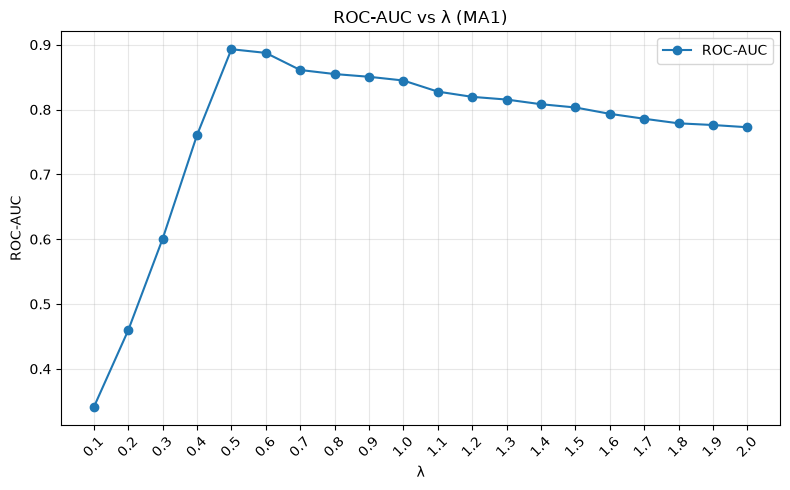

In [11]:
### Cell 8
import matplotlib.pyplot as plt
lambda_list = [0.1, 0.2, 0.3, 0.4, 0.5,
               0.6, 0.7, 0.8, 0.9, 1.0,
               1.1, 1.2, 1.3, 1.4, 1.5,
               1.6, 1.7, 1.8, 1.9, 2.0]
roc_auc_ma1 = [r['ROC-AUC'] for r in all_results['MA1']]

plt.figure(figsize=(8, 5))
plt.plot(lambda_list, roc_auc_ma1, marker='o', linestyle='-',
         color='C0', label='ROC-AUC')
plt.title('ROC-AUC vs λ (MA1)')
plt.xlabel('λ')
plt.ylabel('ROC-AUC')
plt.xticks(lambda_list, rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### 🔴 Section 2: New Idea's

#### ⚪ Variant 1

In [ ]:
### Cell 9
import numpy as np
import time
from sklearn.metrics import roc_auc_score, average_precision_score

def compute_eps_star_star(v, n):
    """Computes the asymmetry-aware adaptive radius (Eq. 8**)."""
    q1, med, q3 = np.percentile(v, [25, 50, 75])
    hl, hu = med - q1, q3 - med
    iqr_eff = 2 * min(hl, hu)
    madn = 1.4826 * np.median(np.abs(v - med))
    
    if madn > 0 or iqr_eff > 0:
        return max(0.9 * min(madn, iqr_eff / 1.34) * (n ** -0.2), 1/n)
    return 0.0

def WNCROD_V1_Adaptive_Radius(data, X_tem, block_size=None):
    """Variant 1: Parameter-free implementation using Eq. 8** (no lammda)."""
    data = np.asarray(data)
    n, m = data.shape
    X_idx = np.ascontiguousarray(X_tem, dtype=np.intp).ravel()
    n_X = X_idx.size
    
    in_X = np.zeros(n, dtype=bool)
    in_X[X_idx] = True
    C_idx = np.flatnonzero(~in_X)

    D1, D2, D3 = m / 3, m / 2, 0.9 * m
    delta = np.zeros(m)
    
    # Calculate adaptive radius per feature (skipping categorical)
    for j in range(m):
        if np.max(data[:, j]) <= 1.0: 
            delta[j] = compute_eps_star_star(data[:, j], n)

    om = np.arange(m + 1)
    s1, s2, s3 = om <= D1, om >= D2, om >= D3
    k1 = m - int(om[s1].max()) if s1.any() else None
    k2 = m - int(om[s2].min()) if s2.any() else None
    k3 = m - int(om[s3].min()) if s3.any() else None

    work = np.ascontiguousarray(data, dtype=np.float64)
    VX = np.ascontiguousarray(work[X_idx].T)
    VC = np.ascontiguousarray(work[C_idx].T)
    
    block_size = int(min(max(1, int(block_size or n_X)), n_X))

    POS = np.empty((m, n_X), dtype=bool)
    hit = np.empty((n_X, m), dtype=np.float64)
    rank_all = np.empty((m, n_X), dtype=np.int32)
    lo_all = np.empty((m, n_X), dtype=np.int32)
    hi_all = np.empty((m, n_X), dtype=np.int32)
    iota = np.arange(n_X, dtype=np.intp)

    for j in range(m):
        v, eps = VX[j], delta[j]
        order = np.argsort(v, kind="stable")
        s = v[order]
        rank = np.empty(n_X, dtype=np.intp)
        rank[order] = iota
        lo, hi = _neighbour_interval(v, s, rank, eps)
        rank_all[j] = rank
        lo_all[j] = lo
        hi_all[j] = hi
        hit[:, j] = hi - lo
        POS[j] = ~_has_outside_neighbour_sorted(v, VC[j], eps)

    NIB = ~POS
    NEB = NIB.all(axis=0)
    NPB = NIB & ~NEB

    gemm_dt = np.float32 if n_X < (1 << 24) else np.float64
    NPB_f = np.ascontiguousarray(NPB.T, dtype=gemm_dt)
    POS_f = np.ascontiguousarray(POS.T, dtype=gemm_dt)

    cnt_dt = np.uint8 if m <= 255 else (np.uint16 if m <= 65535 else np.uint32)
    cnt = np.empty((block_size, n_X), dtype=cnt_dt)
    buf1 = np.empty((block_size, n_X), dtype=bool)
    buf2 = np.empty((block_size, n_X), dtype=bool)
    fbuf = np.empty((block_size, n_X), dtype=gemm_dt)

    neb_cnt = np.zeros(n_X, dtype=np.float64)
    npb_cnt = np.zeros((n_X, m), dtype=np.float64)
    pos_cnt = np.zeros((n_X, m), dtype=np.float64)

    for start in range(0, n_X, block_size):
        stop = min(start + block_size, n_X)
        b = stop - start
        c, a, t = cnt[:b], buf1[:b], buf2[:b]
        c.fill(0)

        for j in range(m):
            r = rank_all[j]
            np.greater_equal(r, lo_all[j][start:stop, None], out=a)
            np.less(r, hi_all[j][start:stop, None], out=t)
            np.logical_and(a, t, out=a)
            c += a

        if k1 is not None:
            np.greater_equal(c, k1, out=a)
            np.logical_and(a, NEB, out=a)
            neb_cnt[start:stop] = np.count_nonzero(a, axis=1)
        if k2 is not None:
            np.less_equal(c, k2, out=a)
            np.copyto(fbuf[:b], a)
            npb_cnt[start:stop] = fbuf[:b] @ NPB_f
        if k3 is not None:
            np.less_equal(c, k3, out=a)
            np.copyto(fbuf[:b], a)
            pos_cnt[start:stop] = fbuf[:b] @ POS_f

    weight = 1 - np.sqrt(hit / n_X)
    ndf = neb_cnt[:, None] + pos_cnt + npb_cnt
    return np.mean((ndf / n_X) * weight, axis=1)

print("\n--- Running Variant 1 (Adaptive Radius - Parameter Free) ---")
print("Note: No grid search or plot is generated since lambda is eliminated.")
for name, X_tem in [('MA1', X_tem_ma1), ('MA2', X_tem_ma2), ('MA3', X_tem_ma3)]:
    t0 = time.perf_counter()
    scores = WNCROD_V1_Adaptive_Radius(X, X_tem)
    auc, ap = roc_auc_score(y[X_tem], scores), average_precision_score(y[X_tem], scores)
    print(f"{name}: ROC-AUC = {auc:.4f} | AP = {ap:.4f} [{time.perf_counter()-t0:.2f} s]")


--- Running Variant 1 (Adaptive Radius - Parameter Free) ---
Note: No grid search or plot is generated since lambda is eliminated.
MA1: ROC-AUC = 0.7751 | AP = 0.0427 [1.68 s]
MA2: ROC-AUC = 0.6601 | AP = 0.0112 [1.32 s]
MA3: ROC-AUC = 0.7154 | AP = 0.0184 [0.92 s]


#### ⚪ Variant 2


--- Running Variant 2 (Global Weighting) Full Grid Search ---
MA1: Best ROC-AUC = 0.9016 (λ=0.55) | Best AP = 0.4215 (λ=0.50) [100.61 s]
MA2: Best ROC-AUC = 0.7623 (λ=0.50) | Best AP = 0.0640 (λ=0.45) [68.37 s]
MA3: Best ROC-AUC = 0.8029 (λ=0.55) | Best AP = 0.1351 (λ=0.55) [46.17 s]


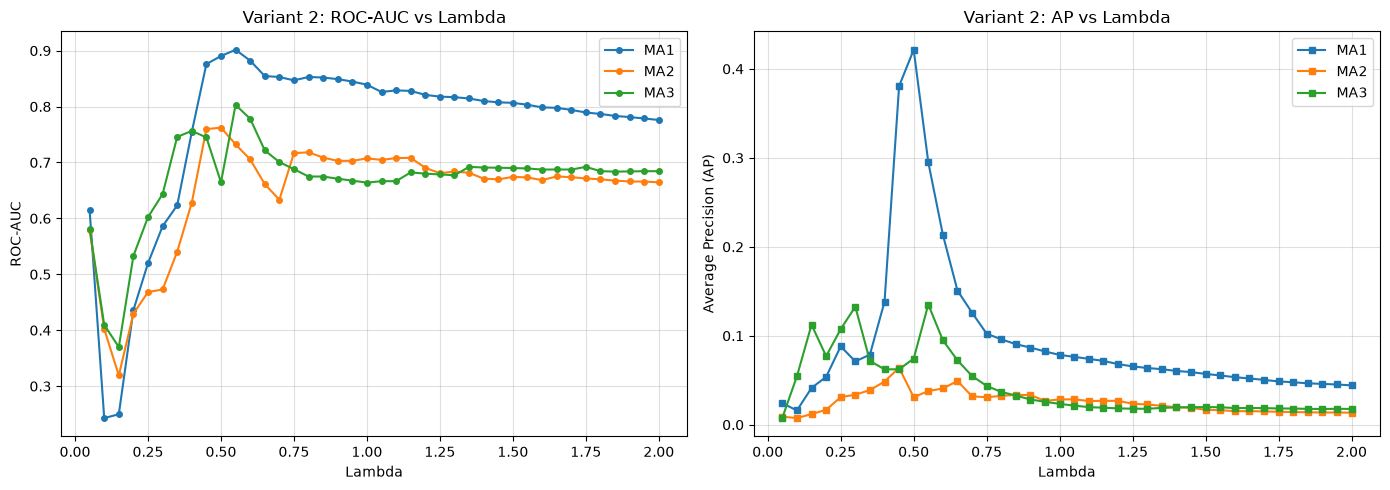

In [25]:
### Cell 10
import matplotlib.pyplot as plt
import numpy as np
import time
from sklearn.metrics import roc_auc_score, average_precision_score

def WNCROD_V2_Global_Weighting(data, X_tem, lammda, block_size=None):
    """Variant 2: Unsupervised dispersion-based weighting (Eq. 12)."""
    data = np.asarray(data)
    n, m = data.shape
    X_idx = np.ascontiguousarray(X_tem, dtype=np.intp).ravel()
    n_X = X_idx.size
    in_X = np.zeros(n, dtype=bool)
    in_X[X_idx] = True
    C_idx = np.flatnonzero(~in_X)
    D1, D2, D3 = m / 3, m / 2, 0.9 * m
    delta = np.zeros(m)
    ID = np.all(data <= 1, axis=0)
    if ID.any():
        delta[ID] = np.std(data[:, ID], axis=0) / lammda

    om = np.arange(m + 1)
    s1, s2, s3 = om <= D1, om >= D2, om >= D3
    k1 = m - int(om[s1].max()) if s1.any() else None
    k2 = m - int(om[s2].min()) if s2.any() else None
    k3 = m - int(om[s3].min()) if s3.any() else None
    work = np.ascontiguousarray(data, dtype=np.float64)
    VX = np.ascontiguousarray(work[X_idx].T)
    VC = np.ascontiguousarray(work[C_idx].T)
    VU = np.ascontiguousarray(work.T) 
    
    block_size = int(min(max(1, int(block_size or n_X)), n_X))
    POS = np.empty((m, n_X), dtype=bool)
    hit = np.empty((n_X, m), dtype=np.float64)
    rank_all = np.empty((m, n_X), dtype=np.int32)
    lo_all = np.empty((m, n_X), dtype=np.int32)
    hi_all = np.empty((m, n_X), dtype=np.int32)
    iota = np.arange(n_X, dtype=np.intp)
    iota_U = np.arange(n, dtype=np.intp)
    cv_array = np.zeros(m)

    for j in range(m):
        v, eps = VX[j], delta[j]
        order = np.argsort(v, kind="stable")
        s = v[order]
        rank = np.empty(n_X, dtype=np.intp)
        rank[order] = iota
        lo, hi = _neighbour_interval(v, s, rank, eps)
        rank_all[j], lo_all[j], hi_all[j] = rank, lo, hi
        hit[:, j] = hi - lo
        POS[j] = ~_has_outside_neighbour_sorted(v, VC[j], eps)
        u_v = VU[j]
        u_order = np.argsort(u_v, kind="stable")
        u_s = u_v[u_order]
        u_rank = np.empty(n, dtype=np.intp)
        u_rank[u_order] = iota_U
        u_lo, u_hi = _neighbour_interval(u_v, u_s, u_rank, eps)
        rho_j = (u_hi - u_lo) / n
        cv_array[j] = np.std(rho_j) / (np.mean(rho_j) + 1/n)

    NIB = ~POS
    NEB = NIB.all(axis=0)
    NPB = NIB & ~NEB

    W_cj = cv_array / np.max(cv_array) if np.max(cv_array) > 0 else np.ones(m)
    gemm_dt = np.float32 if n_X < (1 << 24) else np.float64
    NPB_f, POS_f = np.ascontiguousarray(NPB.T, dtype=gemm_dt), np.ascontiguousarray(POS.T, dtype=gemm_dt)
    cnt = np.empty((block_size, n_X), dtype=np.uint16)
    buf1, buf2 = np.empty((block_size, n_X), dtype=bool), np.empty((block_size, n_X), dtype=bool)
    fbuf = np.empty((block_size, n_X), dtype=gemm_dt)
    neb_cnt, npb_cnt, pos_cnt = np.zeros(n_X), np.zeros((n_X, m)), np.zeros((n_X, m))

    for start in range(0, n_X, block_size):
        stop = min(start + block_size, n_X)
        b = stop - start
        c, a, t = cnt[:b], buf1[:b], buf2[:b]
        c.fill(0)
        for j in range(m):
            r = rank_all[j]
            np.greater_equal(r, lo_all[j][start:stop, None], out=a)
            np.less(r, hi_all[j][start:stop, None], out=t)
            np.logical_and(a, t, out=a)
            c += a
        if k1 is not None:
            neb_cnt[start:stop] = np.count_nonzero((c >= k1) & NEB, axis=1)
        if k2 is not None:
            np.copyto(fbuf[:b], c <= k2)
            npb_cnt[start:stop] = fbuf[:b] @ NPB_f
        if k3 is not None:
            np.copyto(fbuf[:b], c <= k3)
            pos_cnt[start:stop] = fbuf[:b] @ POS_f

    weight_orig = 1 - np.sqrt(hit / n_X)
    omega_star_star = np.sqrt(weight_orig / m) * np.sqrt(W_cj)
    ndf = (neb_cnt[:, None] + pos_cnt + npb_cnt) / n_X
    return np.sum(ndf * omega_star_star, axis=1)

print("\n--- Running Variant 2 (Global Weighting) Full Grid Search ---")
# Grid search range: 0.05 to 2.00 with step 0.05
lambda_list = [round(x * 0.05, 2) for x in range(1, 41)]
v2_history = {name: {'lam': [], 'auc': [], 'ap': []} for name in ['MA1', 'MA2', 'MA3']}

for name, X_tem in [('MA1', X_tem_ma1), ('MA2', X_tem_ma2), ('MA3', X_tem_ma3)]:
    t0 = time.perf_counter()
    
    for lam in lambda_list:
        scores = WNCROD_V2_Global_Weighting(X, X_tem, lammda=lam)
        auc = roc_auc_score(y[X_tem], scores)
        ap = average_precision_score(y[X_tem], scores)
        v2_history[name]['lam'].append(lam)
        v2_history[name]['auc'].append(auc)
        v2_history[name]['ap'].append(ap)
    elapsed = time.perf_counter() - t0
    
    # Extract independent optimums
    b_auc_idx = np.argmax(v2_history[name]['auc'])
    b_ap_idx = np.argmax(v2_history[name]['ap'])
    
    print(f"{name}: Best ROC-AUC = {v2_history[name]['auc'][b_auc_idx]:.4f} (λ={v2_history[name]['lam'][b_auc_idx]:.2f}) | "
          f"Best AP = {v2_history[name]['ap'][b_ap_idx]:.4f} (λ={v2_history[name]['lam'][b_ap_idx]:.2f}) [{elapsed:.2f} s]")

# Plotting V2 Results
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name in ['MA1', 'MA2', 'MA3']:
    axes[0].plot(v2_history[name]['lam'], v2_history[name]['auc'], marker='o', markersize=4, label=name)
    axes[1].plot(v2_history[name]['lam'], v2_history[name]['ap'], marker='s', markersize=4, label=name)

axes[0].set_title('Variant 2: ROC-AUC vs Lambda')
axes[0].set_xlabel('Lambda')
axes[0].set_ylabel('ROC-AUC')
axes[0].legend()
axes[0].grid(True, alpha=0.4)

axes[1].set_title('Variant 2: AP vs Lambda')
axes[1].set_xlabel('Lambda')
axes[1].set_ylabel('Average Precision (AP)')
axes[1].legend()
axes[1].grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

#### ⚪ Variant 3


--- Running Variant 3 (Residual Subspace) Full Grid Search ---
MA1: Best ROC-AUC = 0.8877 (λ=0.55) | Best AP = 0.1690 (λ=0.50) [72.73 s]
MA2: Best ROC-AUC = 0.7852 (λ=0.55) | Best AP = 0.0511 (λ=0.45) [65.45 s]
MA3: Best ROC-AUC = 0.7916 (λ=0.55) | Best AP = 0.0744 (λ=0.15) [45.35 s]


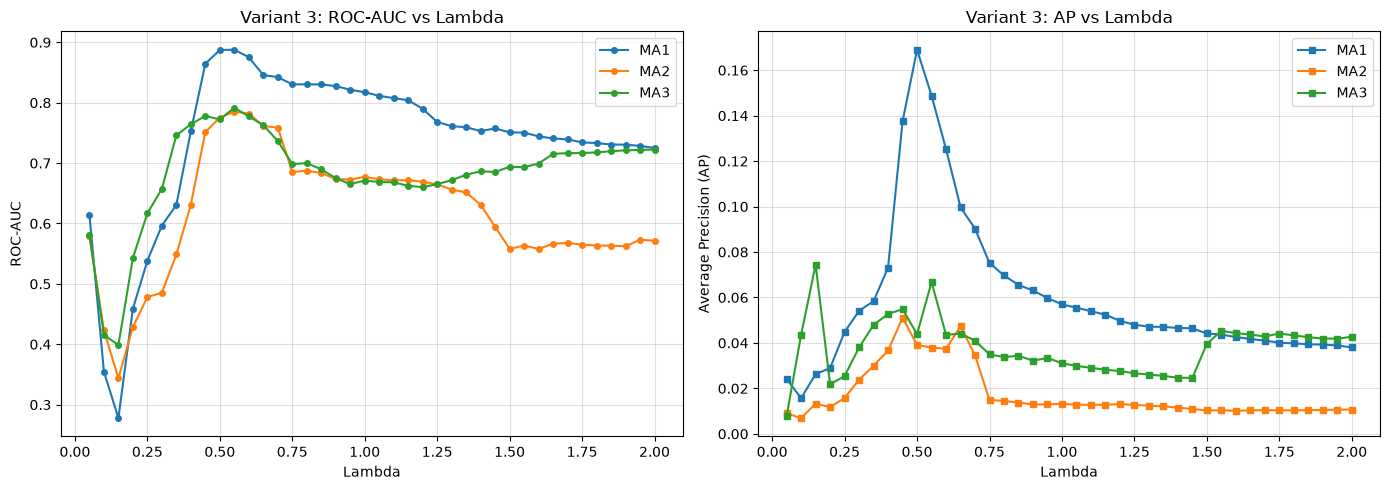

In [26]:
### Cell 11
import matplotlib.pyplot as plt
import numpy as np
import time
from sklearn.metrics import roc_auc_score, average_precision_score

def synthesize_subspace_attribute(data, t_max=10):
    """Algorithm 0*: Injects subspace attribute with dimension cap (Section 3.2)."""
    data = np.asarray(data, dtype=np.float64)
    n, m = data.shape
    is_num = np.all(data <= 1, axis=0)
    m_num = np.sum(is_num)
    if m_num < 2:
        return data
        
    Z = np.zeros((n, m_num))
    num_cols = np.where(is_num)[0]
    
    for i, col in enumerate(num_cols):
        v = data[:, col]
        med = np.median(v)
        madn = 1.4826 * np.median(np.abs(v - med))
        Z[:, i] = (v - med) / madn if madn > 0 else 0
        
    r = min(int(np.ceil(np.log2(m_num + 1))), m_num - 1)
    if r < 1:
        return data

    V = []
    Z_k = Z.copy()
    rnd = np.random.RandomState(42)
    for k in range(r):
        u = rnd.randn(m_num)
        u /= np.linalg.norm(u)
        for _ in range(t_max):
            u = Z_k.T @ (Z_k @ u)
            norm_u = np.linalg.norm(u)
            if norm_u > 0: u /= norm_u
        V.append(u)
        Z_k = Z_k - np.outer(Z_k @ u, u)

    J = np.sum(Z**2, axis=1) - sum((Z @ v)**2 for v in V)
    J = np.clip(J, 0, None)
    c_m1 = np.zeros(n)
    if J.max() > J.min():
        c_m1 = (J - J.min()) / (J.max() - J.min())
        
    return np.column_stack([data, c_m1])

print("\n--- Running Variant 3 (Residual Subspace) Full Grid Search ---")
X_augmented = synthesize_subspace_attribute(X)
# Grid search range: 0.05 to 2.00 with step 0.05
lambda_list = [round(x * 0.05, 2) for x in range(1, 41)]
v3_history = {name: {'lam': [], 'auc': [], 'ap': []} for name in ['MA1', 'MA2', 'MA3']}

for name, X_tem in [('MA1', X_tem_ma1), ('MA2', X_tem_ma2), ('MA3', X_tem_ma3)]:
    t0 = time.perf_counter()
    for lam in lambda_list:
        scores = WNCROD_optimized(X_augmented, X_tem, lammda=lam)
        auc = roc_auc_score(y[X_tem], scores)
        ap = average_precision_score(y[X_tem], scores)
        v3_history[name]['lam'].append(lam)
        v3_history[name]['auc'].append(auc)
        v3_history[name]['ap'].append(ap)
    elapsed = time.perf_counter() - t0
    
    # Extract independent optimums
    b_auc_idx = np.argmax(v3_history[name]['auc'])
    b_ap_idx = np.argmax(v3_history[name]['ap'])
    
    print(f"{name}: Best ROC-AUC = {v3_history[name]['auc'][b_auc_idx]:.4f} (λ={v3_history[name]['lam'][b_auc_idx]:.2f}) | "
          f"Best AP = {v3_history[name]['ap'][b_ap_idx]:.4f} (λ={v3_history[name]['lam'][b_ap_idx]:.2f}) [{elapsed:.2f} s]")

# Plotting V3 Results
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name in ['MA1', 'MA2', 'MA3']:
    axes[0].plot(v3_history[name]['lam'], v3_history[name]['auc'], marker='o', markersize=4, label=name)
    axes[1].plot(v3_history[name]['lam'], v3_history[name]['ap'], marker='s', markersize=4, label=name)

axes[0].set_title('Variant 3: ROC-AUC vs Lambda')
axes[0].set_xlabel('Lambda')
axes[0].set_ylabel('ROC-AUC')
axes[0].legend()
axes[0].grid(True, alpha=0.4)
axes[1].set_title('Variant 3: AP vs Lambda')
axes[1].set_xlabel('Lambda')
axes[1].set_ylabel('Average Precision (AP)')
axes[1].legend()
axes[1].grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

#### ⚪ Variant 4


--- Running Variant 4 (Calibrated Voting) Full Grid Search ---
MA1: Best ROC-AUC = 0.8929 (λ=0.50) | Best AP = 0.2177 (λ=0.50) [163.05 s]
MA2: Best ROC-AUC = 0.7141 (λ=0.60) | Best AP = 0.0424 (λ=0.60) [138.76 s]
MA3: Best ROC-AUC = 0.7615 (λ=0.60) | Best AP = 0.1693 (λ=0.95) [93.87 s]


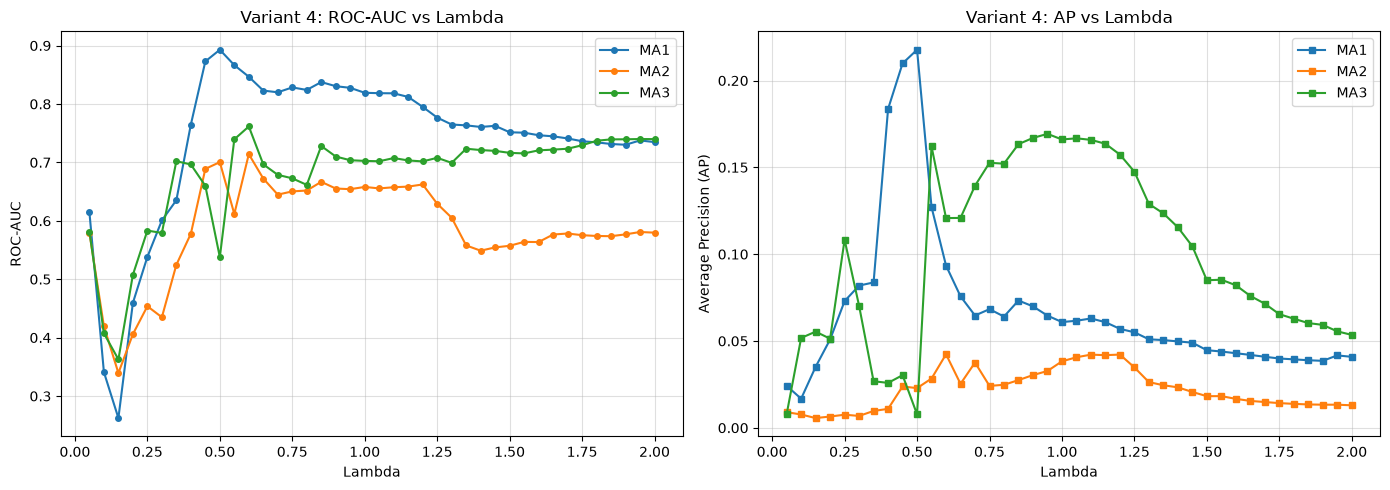

In [27]:
### Cell 12
import matplotlib.pyplot as plt
import numpy as np
import time
from sklearn.metrics import roc_auc_score, average_precision_score

def WNCROD_V4_Calibrated_Voting(data, X_tem, lammda, block_size=None):
    """Variant 4: Implements rate-calibrated cross-attribute voting (Eq. 11)."""
    data = np.asarray(data)
    n, m = data.shape
    X_idx = np.ascontiguousarray(X_tem, dtype=np.intp).ravel()
    n_X = X_idx.size
    in_X = np.zeros(n, dtype=bool)
    in_X[X_idx] = True
    C_idx = np.flatnonzero(~in_X)
    D1, D2, D3 = m / 3, m / 2, 0.9 * m
    delta = np.zeros(m)
    ID = np.all(data <= 1, axis=0)
    if ID.any(): delta[ID] = np.std(data[:, ID], axis=0) / lammda
    work = np.ascontiguousarray(data, dtype=np.float64)
    VX = np.ascontiguousarray(work[X_idx].T)
    VC = np.ascontiguousarray(work[C_idx].T)
    VU = np.ascontiguousarray(work.T)
    
    block_size = int(min(max(1, int(block_size or n_X)), n_X))
    POS = np.empty((m, n_X), dtype=bool)
    hit = np.empty((n_X, m), dtype=np.float64)
    rank_all = np.empty((m, n_X), dtype=np.int32)
    lo_all = np.empty((m, n_X), dtype=np.int32)
    hi_all = np.empty((m, n_X), dtype=np.int32)
    iota = np.arange(n_X, dtype=np.intp)
    iota_U = np.arange(n, dtype=np.intp)
    q_j = np.zeros(m)

    for j in range(m):
        v, eps = VX[j], delta[j]
        order = np.argsort(v, kind="stable")
        s = v[order]
        rank = np.empty(n_X, dtype=np.intp)
        rank[order] = iota
        lo, hi = _neighbour_interval(v, s, rank, eps)
        rank_all[j], lo_all[j], hi_all[j] = rank, lo, hi
        hit[:, j] = hi - lo
        POS[j] = ~_has_outside_neighbour_sorted(v, VC[j], eps)
        u_v = VU[j]
        u_order = np.argsort(u_v, kind="stable")
        u_s = u_v[u_order]
        u_rank = np.empty(n, dtype=np.intp)
        u_rank[u_order] = iota_U
        u_lo, u_hi = _neighbour_interval(u_v, u_s, u_rank, eps)
        inside_pairs = np.sum(u_hi - u_lo) - n 
        q_j[j] = 1.0 - (inside_pairs / (n * (n - 1)))
        
    q_bar = np.mean(q_j)
    q_j_dagger = np.maximum(q_j, 1/n)
    I_j_weights = np.where(q_j > 0, q_bar / q_j_dagger, 0.0).astype(np.float32)

    NIB = ~POS
    NEB = NIB.all(axis=0)
    NPB = NIB & ~NEB

    gemm_dt = np.float32 if n_X < (1 << 24) else np.float64
    NPB_f, POS_f = np.ascontiguousarray(NPB.T, dtype=gemm_dt), np.ascontiguousarray(POS.T, dtype=gemm_dt)
    buf1, buf2 = np.empty((block_size, n_X), dtype=bool), np.empty((block_size, n_X), dtype=bool)
    fbuf = np.empty((block_size, n_X), dtype=gemm_dt)
    nom_ss = np.zeros((block_size, n_X), dtype=np.float32) 
    neb_cnt, npb_cnt, pos_cnt = np.zeros(n_X), np.zeros((n_X, m)), np.zeros((n_X, m))

    for start in range(0, n_X, block_size):
        stop = min(start + block_size, n_X)
        b = stop - start
        a, t = buf1[:b], buf2[:b]
        nom_ss[:b].fill(0.0)

        for j in range(m):
            r = rank_all[j]
            np.greater_equal(r, lo_all[j][start:stop, None], out=a)
            np.less(r, hi_all[j][start:stop, None], out=t)
            np.logical_and(a, t, out=a)
            if I_j_weights[j] > 0:
                nom_ss[:b] += (~a).astype(np.float32) * I_j_weights[j]

        neb_cnt[start:stop] = np.count_nonzero((nom_ss[:b] <= D1) & NEB, axis=1)
        np.copyto(fbuf[:b], nom_ss[:b] >= D2)
        npb_cnt[start:stop] = fbuf[:b] @ NPB_f
        np.copyto(fbuf[:b], nom_ss[:b] >= D3)
        pos_cnt[start:stop] = fbuf[:b] @ POS_f

    weight = 1 - np.sqrt(hit / n_X)
    ndf = neb_cnt[:, None] + pos_cnt + npb_cnt
    return np.mean((ndf / n_X) * weight, axis=1)

print("\n--- Running Variant 4 (Calibrated Voting) Full Grid Search ---")
# Grid search range: 0.05 to 2.00 with step 0.05
lambda_list = [round(x * 0.05, 2) for x in range(1, 41)]
v4_history = {name: {'lam': [], 'auc': [], 'ap': []} for name in ['MA1', 'MA2', 'MA3']}

for name, X_tem in [('MA1', X_tem_ma1), ('MA2', X_tem_ma2), ('MA3', X_tem_ma3)]:
    t0 = time.perf_counter()
    for lam in lambda_list:
        scores = WNCROD_V4_Calibrated_Voting(X, X_tem, lammda=lam)
        auc = roc_auc_score(y[X_tem], scores)
        ap = average_precision_score(y[X_tem], scores)
        v4_history[name]['lam'].append(lam)
        v4_history[name]['auc'].append(auc)
        v4_history[name]['ap'].append(ap)
    elapsed = time.perf_counter() - t0
    
    # Extract independent optimums
    b_auc_idx = np.argmax(v4_history[name]['auc'])
    b_ap_idx = np.argmax(v4_history[name]['ap'])
    
    print(f"{name}: Best ROC-AUC = {v4_history[name]['auc'][b_auc_idx]:.4f} (λ={v4_history[name]['lam'][b_auc_idx]:.2f}) | "
          f"Best AP = {v4_history[name]['ap'][b_ap_idx]:.4f} (λ={v4_history[name]['lam'][b_ap_idx]:.2f}) [{elapsed:.2f} s]")

# Plotting V4 Results
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name in ['MA1', 'MA2', 'MA3']:
    axes[0].plot(v4_history[name]['lam'], v4_history[name]['auc'], marker='o', markersize=4, label=name)
    axes[1].plot(v4_history[name]['lam'], v4_history[name]['ap'], marker='s', markersize=4, label=name)

axes[0].set_title('Variant 4: ROC-AUC vs Lambda')
axes[0].set_xlabel('Lambda')
axes[0].set_ylabel('ROC-AUC')
axes[0].legend()
axes[0].grid(True, alpha=0.4)
axes[1].set_title('Variant 4: AP vs Lambda')
axes[1].set_xlabel('Lambda')
axes[1].set_ylabel('Average Precision (AP)')
axes[1].legend()
axes[1].grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

#### ⚪ 5. 